# Wine quality - JarvisTEC (`wine`)

**Team member(s):** _fill in_
**Dataset:** [Wine Quality (Kaggle, rajyellow46/wine-quality)](https://www.kaggle.com/datasets/rajyellow46/wine-quality), a version with missing values of the Cortez et al. (2009) dataset from the UCI Machine Learning Repository.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

> **Note:** the analysis text is a draft written from this notebook's results. The team must review it, adjust it with its own judgment and fill in the team members before submission.

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "wine"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/wine_quality/winequalityN.csv"
TARGET_COLUMN = "quality_class"  # derived from `quality`, section 2
TASK_TYPE = "classification"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# The raw score defines the class, so it cannot be an input.
EXCLUDED_COLUMNS = ["quality"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate the **sensory quality of a wine** (low, medium or high) from 11 physicochemical lab measurements and the wine type (red or white). It is useful to a producer or a lab that wants a fast, cheap first classification before (or instead of) a tasting panel, and to prioritize batches.

- **Task type:** multiclass classification. The raw score is an integer from 3 to 9, but it is heavily concentrated on 5 and 6 (only 5 wines scored 9 and 30 scored 3), so predicting the exact score would leave classes with almost no examples. It is grouped into three practical classes: **low** (3-5), **medium** (6) and **high** (7-9).
- **Success metric:** **macro F1**, which averages the F1 of the three classes with equal weight. Accuracy would reward predicting only the majority class; here the priority is not to miss the high-quality wines, the minority class. The model is always compared with a baseline that predicts the most frequent class.
- **Support:** Cortez et al. (2009), the dataset authors, modeled wine quality from these same physicochemical properties with data-mining techniques (multiple regression, neural networks and SVM).

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
# snake_case names: the same fields the API receives
# (backend/models/wine/schema.py).
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

# Target: the 3-9 score grouped into three classes (see section 3).
CLASS_BINS = {"low": (3, 5), "medium": (6, 6), "high": (7, 9)}


def to_class(score):
    return next(
        label for label, (low, high) in CLASS_BINS.items()
        if low <= score <= high
    )


df[TARGET_COLUMN] = df["quality"].map(to_class)
display(df.head())

,type,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,quality_class
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,medium
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,medium
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,medium
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,medium
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,medium


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
type,str,0,0.00,2
fixed_acidity,float64,10,0.15,106
volatile_acidity,float64,8,0.12,187
citric_acid,float64,3,0.05,89
residual_sugar,float64,2,0.03,316
chlorides,float64,2,0.03,214
free_sulfur_dioxide,float64,0,0.00,135
total_sulfur_dioxide,float64,0,0.00,276
density,float64,0,0.00,998
ph,float64,9,0.14,108


Duplicated rows: 1168


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
type,6497,2,white,4898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fixed_acidity,6487.0,NaN,NaN,NaN,7.216579,1.29675,3.8,6.4,7.0,7.7,15.9
volatile_acidity,6489.0,NaN,NaN,NaN,0.339691,0.164649,0.08,0.23,0.29,0.4,1.58
citric_acid,6494.0,NaN,NaN,NaN,0.318722,0.145265,0.0,0.25,0.31,0.39,1.66
residual_sugar,6495.0,NaN,NaN,NaN,5.444326,4.758125,0.6,1.8,3.0,8.1,65.8
chlorides,6495.0,NaN,NaN,NaN,0.056042,0.035036,0.009,0.038,0.047,0.065,0.611
free_sulfur_dioxide,6497.0,NaN,NaN,NaN,30.525319,17.7494,1.0,17.0,29.0,41.0,289.0
total_sulfur_dioxide,6497.0,NaN,NaN,NaN,115.744574,56.521855,6.0,77.0,118.0,156.0,440.0
density,6497.0,NaN,NaN,NaN,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
ph,6488.0,NaN,NaN,NaN,3.218395,0.160748,2.72,3.11,3.21,3.32,4.01


**Data description.** *Wine Quality* dataset of Portuguese *vinho verde* wines (Cortez et al., 2009), in the Kaggle version `winequalityN.csv`, which includes a few missing values. It has **6497 wines** (1599 red, 4898 white) and 13 columns:

| Variable | Meaning | Type / unit |
|---|---|---|
| `type` | wine type | categorical: `red`, `white` |
| `fixed_acidity` | fixed acidity (tartaric acid) | g/dm3 |
| `volatile_acidity` | volatile acidity (acetic acid); too much tastes like vinegar | g/dm3 |
| `citric_acid` | citric acid | g/dm3 |
| `residual_sugar` | sugar left after fermentation | g/dm3 |
| `chlorides` | sodium chloride | g/dm3 |
| `free_sulfur_dioxide` | free SO2 (preservative) | mg/dm3 |
| `total_sulfur_dioxide` | total SO2 (free + bound) | mg/dm3 |
| `density` | density | g/cm3 |
| `ph` | acidity on the pH scale | 0-14 |
| `sulphates` | potassium sulphate (additive) | g/dm3 |
| `alcohol` | alcohol content | % vol. |
| `quality` | median of the scores of at least 3 tasters | integer 0-10 (here 3-9) |

**Data quality:**
- **Missing values:** 38 values in 7 numeric columns (at most 10 in `fixed_acidity`, 0.15 %), spread over 34 rows. They are few, so they are imputed with the median inside the `Pipeline` instead of dropping rows; this way the backend also tolerates a missing value.
- **Duplicates:** **1168 identical rows** (18 %). They are removed before splitting: if one copy lands in training and another in test, the evaluation would be optimistic. **5329 wines** remain.
- There are no identifier columns and no obviously impossible values; extreme values are analyzed in the exploration.
- `quality` is excluded from the inputs because the target `quality_class` is derived from it.

## 3. Data exploration

type,red,white,All
quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5
All,1599,4898,6497


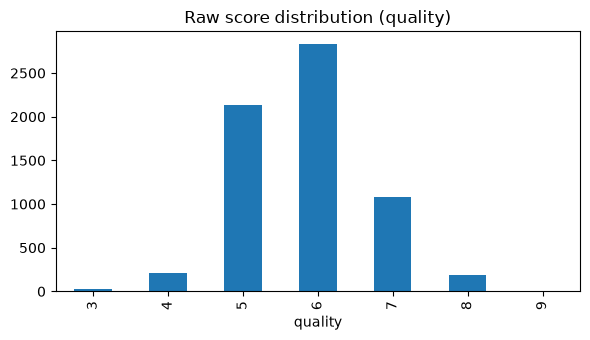

In [5]:
# Raw score before grouping, overall and by wine type.
display(pd.crosstab(df["quality"], df["type"], margins=True))
fig, ax = plt.subplots(figsize=(6, 3.5))
df["quality"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Raw score distribution (quality)")
plt.tight_layout()
plt.show()

quality_class
medium    43.65
low       36.69
high      19.66
Name: % of each class, dtype: float64

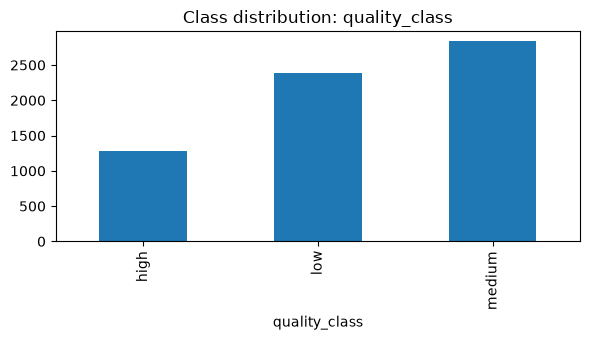

In [6]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

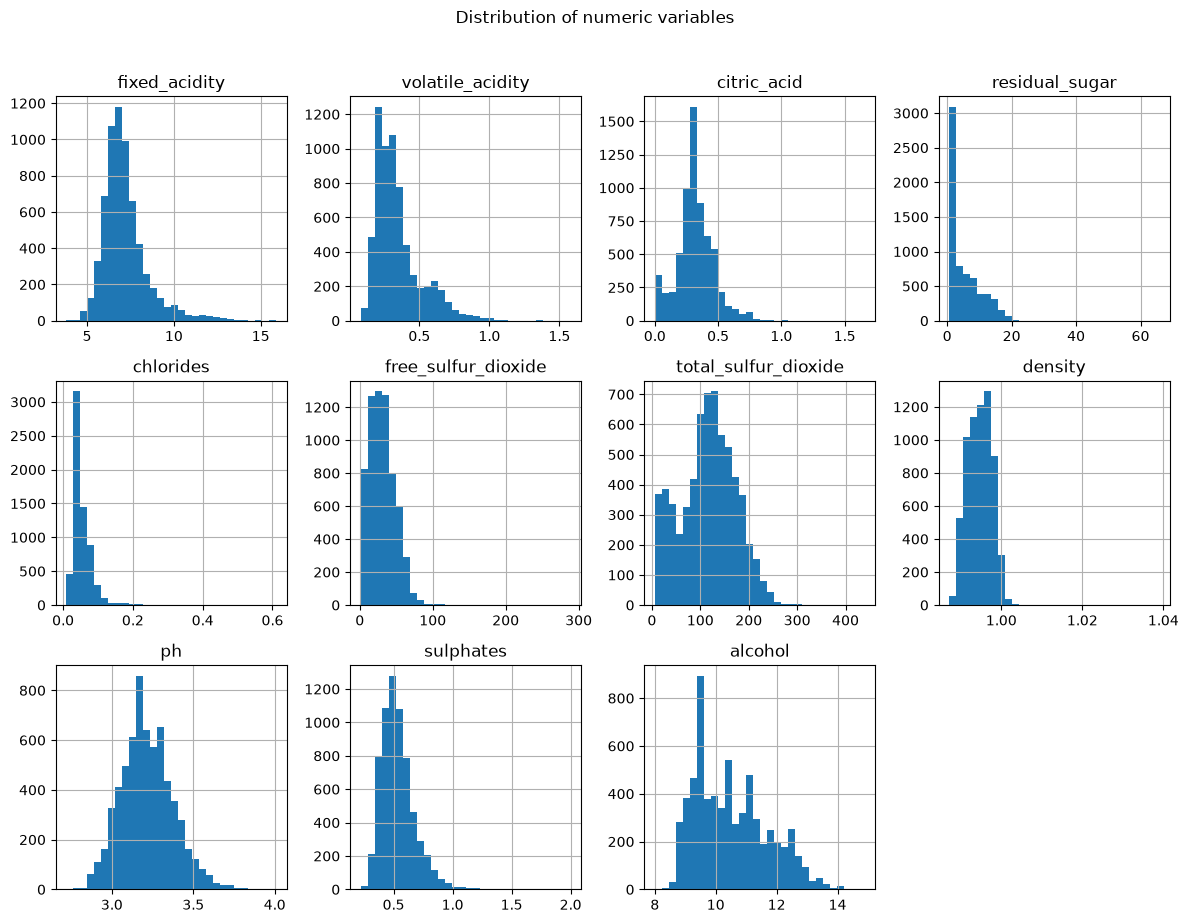

In [7]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

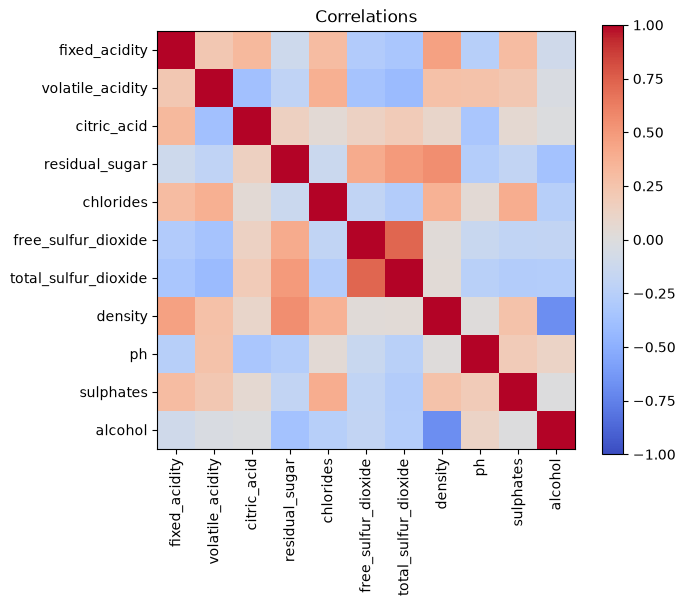

In [8]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [9]:
# The target is categorical: correlation is measured against the raw score.
display(
    df[numeric_columns + ["quality"]].corr()["quality"].drop("quality")
    .sort_values(key=abs, ascending=False)
    .rename("correlation with quality")
)
display(
    pd.crosstab(df["type"], df[TARGET_COLUMN], normalize="index").round(3)
)

alcohol                 0.444319
density                -0.305858
volatile_acidity       -0.265953
chlorides              -0.200886
citric_acid             0.085706
fixed_acidity          -0.077031
free_sulfur_dioxide     0.055463
total_sulfur_dioxide   -0.041385
sulphates               0.038729
residual_sugar         -0.036825
ph                      0.019366
Name: correlation with quality, dtype: float64

quality_class,high,low,medium
type,,,
red,0.136,0.465,0.399
white,0.216,0.335,0.449


In [10]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


type: 2 categories


type
white    4898
red      1599
Name: count, dtype: int64

**Exploration findings:**

- **Imbalance:** after grouping, the classes are 43.7 % medium, 36.7 % low and 19.7 % high. The imbalance is moderate; the project uses macro F1, a stratified split, and tries `class_weight="balanced"` during tuning.
- **Relationship with quality:** **alcohol** is the variable most associated with the score (correlation 0.44), followed by **density** (-0.31), **volatile acidity** (-0.27) and **chlorides** (-0.20). The rest have linear correlations below 0.1, which suggests a linear model will not be enough.
- **Redundant variables:** density is strongly tied to alcohol (-0.69) and residual sugar (0.55), and free SO2 to total SO2 (0.72). They are kept because tree models tolerate redundancy, but this must be considered when interpreting importances.
- **Red vs. white:** they are chemically different (median total SO2 38 vs. 134 mg/dm3; volatile acidity 0.52 vs. 0.26 g/dm3), and red wines have a larger share of low quality (46.5 % vs. 33.5 %). That is why `type` stays as an input, one-hot encoded.
- **Outliers:** several variables have long tails (e.g. free SO2 up to 289 mg/dm3 while 75 % is below 41; residual sugar up to 65.8 g/dm3). By the IQR rule, citric acid has 7.8 % outliers and volatile acidity 5.8 %. They are kept: they are plausible measurements of real wines, and decision trees are barely sensitive to them.

**Preprocessing decisions:** drop duplicates; impute missing values with the median (numeric) or the mode (`type`); scale numeric variables and one-hot encode `type`, all inside the `Pipeline`.

## 4. Model

A baseline is compared with several models using cross-validation, and the best one is chosen. All preprocessing lives inside a `Pipeline`, so the backend receives raw data and there is no information leakage.

> **Time series:** with `IS_TIME_SERIES = True` the split is chronological (the test set is the most recent data) and cross-validation uses `TimeSeriesSplit`. Never shuffle the temporal order when splitting.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        else KFold(5, shuffle=True, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (4263, 12)  Test: (1066, 12)
Numeric: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']
Categorical: ['type']


In [12]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LogisticRegression, Ridge

if TASK_TYPE == "classification":
    candidates = {
        "Baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": LogisticRegression(max_iter=1000),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, random_state=SEED, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    }
    scoring = "f1_macro"
else:
    candidates = {
        "Baseline": DummyRegressor(strategy="mean"),
        "Ridge": Ridge(),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, random_state=SEED, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    }
    # Negative RMSE: higher is better.
    scoring = "neg_root_mean_squared_error"

score_column = f"{scoring} (mean)"
rows = []
for name, estimator in candidates.items():
    pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1
    )
    rows.append({
        "model": name,
        score_column: scores.mean(),
        "std": scores.std(),
    })
comparison = (
    pd.DataFrame(rows)
    .sort_values(score_column, ascending=False)
    .reset_index(drop=True)
)
display(comparison)

,model,f1_macro (mean),std
0,Random Forest,0.587147,0.016015
1,Gradient Boosting,0.563752,0.010998
2,Logistic regression,0.555587,0.023089
3,Baseline,0.202591,0.000140


**Model choice.** Four models were compared with stratified 5-fold cross-validation on the training set:
- a **baseline** that always predicts the most frequent class;
- **logistic regression**, a linear and interpretable model;
- two tree ensembles: **Random Forest** (Breiman, 2001) and **Gradient Boosting** (Friedman, 2001).

**Random Forest** had the best macro F1 (0.587, against 0.564 for Gradient Boosting, 0.556 for logistic regression and 0.203 for the baseline). This agrees with the exploration: the relationship between the chemical variables and quality is weak and non-linear, and a tree ensemble captures interactions (e.g. alcohol with volatile acidity) without linearity assumptions and with little sensitivity to outliers.

**Hyperparameter tuning.** `RandomizedSearchCV` evaluated 20 combinations with the same cross-validation, on the training set only:
- **Searched hyperparameters:** number of trees, maximum depth, minimum samples per leaf, fraction of features per split and `class_weight`.
- **Best combination:** 400 trees, no depth limit, `min_samples_leaf=2`, `max_features="sqrt"` and **`class_weight="balanced"`**.
- **Result:** the cross-validated macro F1 rose from 0.587 to 0.598, so it was adopted. Balanced weights compensate for the high class having half as many examples as the others.

In [13]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates[BEST]),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Random Forest


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['high','low','medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['type','fixed_acidity','volatile_acidity',...,'ph','sulphates','alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

In [14]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.5],
        "model__class_weight": [None, "balanced"],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 400],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0],
    },
}
if TASK_TYPE == "regression":
    SEARCH_SPACES["Random Forest"].pop("model__class_weight")

HYPERPARAMETERS = {}
if BEST in SEARCH_SPACES:
    search = RandomizedSearchCV(
        final_pipeline,
        SEARCH_SPACES[BEST],
        n_iter=20,
        cv=cv,
        scoring=scoring,
        random_state=SEED,
        n_jobs=1,
    )
    search.fit(X_train, y_train)
    untuned = comparison.loc[comparison["model"].eq(BEST), score_column]
    untuned = untuned.iloc[0]
    print(
        f"{scoring} CV untuned: {untuned:.4f} | "
        f"tuned: {search.best_score_:.4f}"
    )
    if search.best_score_ > untuned:
        final_pipeline = search.best_estimator_
        HYPERPARAMETERS = {
            key.removeprefix("model__"): value
            for key, value in search.best_params_.items()
        }
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")

f1_macro CV untuned: 0.5871 | tuned: 0.5984
Hyperparameters used: {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced'}


## 5. Evaluation

The model is evaluated **only once** on the test set, which it has never seen.

              precision    recall  f1-score   support

        high       0.51      0.67      0.58       202
         low       0.66      0.70      0.68       398
      medium       0.58      0.46      0.51       466

    accuracy                           0.59      1066
   macro avg       0.58      0.61      0.59      1066
weighted avg       0.59      0.59      0.59      1066



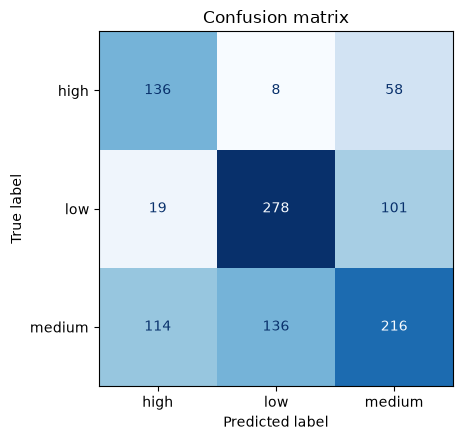

accuracy           0.5910
f1_macro           0.5897
precision_macro    0.5801
recall_macro       0.6118
Name: test metrics, dtype: float64

Baseline f1_macro on test: 0.2028


In [15]:
from sklearn import metrics

predictions = final_pipeline.predict(X_test)

if TASK_TYPE == "classification":
    test_metrics = {
        "accuracy": metrics.accuracy_score(y_test, predictions),
        "f1_macro": metrics.f1_score(y_test, predictions, average="macro"),
        "precision_macro": metrics.precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": metrics.recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    print(metrics.classification_report(
        y_test, predictions, zero_division=0
    ))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    plt.show()
else:
    test_metrics = {
        "rmse": metrics.mean_squared_error(y_test, predictions) ** 0.5,
        "mae": metrics.mean_absolute_error(y_test, predictions),
        "r2": metrics.r2_score(y_test, predictions),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(y_test, predictions, alpha=0.4)
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max()),
    ]
    ax[0].plot(limits, limits, "r--")
    ax[0].set_xlabel("Actual")
    ax[0].set_ylabel("Predicted")
    ax[0].set_title("Actual vs. predicted")
    ax[1].hist(y_test - predictions, bins=40)
    ax[1].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baseline on the same test set, to check the model really adds value.
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates["Baseline"]),
]).fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
if TASK_TYPE == "classification":
    baseline_score = metrics.f1_score(
        y_test, baseline_predictions, average="macro"
    )
    print("Baseline f1_macro on test:", round(baseline_score, 4))
else:
    baseline_score = (
        metrics.mean_squared_error(y_test, baseline_predictions) ** 0.5
    )
    print("Baseline RMSE on test:", round(baseline_score, 4))

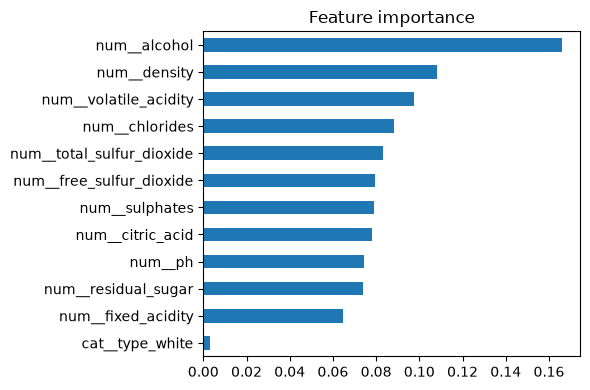

In [16]:
# Feature importance (when the model exposes it).
estimator = final_pipeline.named_steps["model"]
if hasattr(estimator, "feature_importances_"):
    feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
    importance = (
        pd.Series(estimator.feature_importances_, index=feature_names)
        .sort_values()
        .tail(12)
    )
    importance.plot(kind="barh", figsize=(6, 4), title="Feature importance")
    plt.tight_layout()
    plt.show()

**Interpretation.** On the test set (1066 unseen wines) the model reaches **macro F1 0.590** and **accuracy 0.591**, against a baseline macro F1 of **0.203**. The model learns a real signal, but 41 % of the wines are misclassified: chemistry explains only part of the perceived quality.

**Error analysis (confusion matrix):**
- **By class:** the **low** class is recognized best (F1 0.68). The **high** class reaches recall 0.67: it finds two out of three good wines, at the cost of a precision of 0.51. The **medium** class is the hardest (F1 0.51, recall 0.46), because it sits between the other two.
- **Error type:** almost all errors happen between **neighboring** classes. Only 8 high-quality wines were predicted as low, and 19 low-quality wines as high. A score of 6 (medium) and a 7 (high) can differ by one taster's opinion.
- **By wine type:** performance is lower on red wines (macro F1 0.54) than on white wines (0.60); there are three times fewer red wines in the data.

**Effect of tuning.** The untuned model reached a test macro F1 of 0.600, with recall 0.48 on the high class and 0.62 on the medium class. The tuned model shifts that balance: it finds many more good wines (0.67) at the cost of confusing more medium wines (0.46). The model chosen by cross-validation is kept, because using the test set to choose the model would invalidate the evaluation. Both results are compatible within the variation observed across folds (standard deviation about 0.016).

**Feature importance.** **Alcohol** is the most important variable (0.17), followed by density, volatile acidity and chlorides, in line with the exploration's correlations. `type` adds almost nothing directly, because its effect is already reflected in variables such as SO2 and volatile acidity.

**Possible causes of error:** the quality score is subjective (median of tasters); variables that affect taste are missing (grape, year, price, aging); the imbalance is moderate; and the classes are arbitrary cuts of a continuous scale.

## Export for the backend

In [17]:
joblib.dump(final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# Typical input: becomes the `default_input` of the backend adapter.
example = X_train.median(numeric_only=True).round(3).to_dict()
for column in categorical_features:
    example[column] = X_train[column].mode().iloc[0]

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "default_input": example,
    "sklearn_version": sklearn.__version__,
}
if TASK_TYPE == "classification":
    meta["classes"] = sorted(y.unique().tolist())
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))

Saved artifacts/wine.joblib and wine.meta.json

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "fixed_acidity": 7.0,
  "volatile_acidity": 0.3,
  "citric_acid": 0.31,
  "residual_sugar": 2.8,
  "chlorides": 0.047,
  "free_sulfur_dioxide": 28.0,
  "total_sulfur_dioxide": 117.0,
  "density": 0.995,
  "ph": 3.22,
  "sulphates": 0.51,
  "alcohol": 10.4,
  "type": "white"
}


## 6. Conclusion

A Random Forest with balanced class weights classifies wine quality as low, medium or high with a **test macro F1 of 0.59**, almost three times the baseline (0.20). It separates clearly bad wines from clearly good ones, and its errors concentrate between neighboring classes. The most influential variables (alcohol, density, volatile acidity) match what enology would expect. It is useful as a **guiding filter**, not as a replacement for a tasting panel.

**Limitations:**
- Quality is a subjective perception.
- The data comes from a single Portuguese denomination of origin, so it may not generalize to other wines.
- Performance is lower on red wines.
- The medium class, the most frequent one, is the worst recognized.

**Future improvements:**
- Try separate models per wine type.
- Frame the problem as ordinal regression of the score.
- Evaluate Gradient Boosting with a wider search.
- Tune the decision thresholds depending on whether missing good wines or overestimating quality matters more.

**Voice commands for this model:** *"JarvisTEC, calidad del vino"*, *"JarvisTEC, clasificar vino"*, *"JarvisTEC, que tan bueno es este vino"*

### References

- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547-553. https://doi.org/10.1016/j.dss.2009.05.016
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.